Name : Aishi De
Sec : A
Sem :  7
PRN : 23070521008
Batch : A1

Aim :
Hyperparameter Tuning and Model Optimization. Problem Statement: Improve deep learning
model performance through tuning learning rate, batch size, number of layers, and activation
functions. Activities: Experiment with optimizers; Tune model parameters; Compare
validation accuracy.

In [5]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Active Device: {device}")
if device.type == "cpu":
    print("💡 TIP: For maximum speed, switch to GPU in Colab (Runtime -> Change runtime type -> T4 GPU).")

# 2. Load Fashion-MNIST ONCE directly into Device Memory (VRAM/RAM)
print("\n[*] Loading and caching dataset...")
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_ds = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
val_ds = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Pre-process & flatten images into 2D tensors directly on target device
X_train = (train_ds.data.float().view(-1, 784) / 255.0 - 0.5) / 0.5
y_train = train_ds.targets
X_val = (val_ds.data.float().view(-1, 784) / 255.0 - 0.5) / 0.5
y_val = val_ds.targets

X_train, y_train = X_train.to(device), y_train.to(device)
X_val, y_val = X_val.to(device), y_val.to(device)

print(f"[+] Dataset cached on device! Train size: {X_train.shape[0]}, Val size: {X_val.shape[0]}")

[+] Active Device: cpu
💡 TIP: For maximum speed, switch to GPU in Colab (Runtime -> Change runtime type -> T4 GPU).

[*] Loading and caching dataset...
[+] Dataset cached on device! Train size: 60000, Val size: 10000


In [6]:
class DynamicMLP(nn.Module):
    """
    Accepts dynamic hidden layer counts, unit sizes, and activation functions.
    """
    def __init__(self, input_dim=784, num_classes=10, hidden_units=[128, 64], activation="relu"):
        super(DynamicMLP, self).__init__()

        activations = {
            "relu": nn.ReLU(),
            "leaky_relu": nn.LeakyReLU(0.1),
            "tanh": nn.Tanh(),
            "sigmoid": nn.Sigmoid()
        }
        act_layer = activations.get(activation.lower(), nn.ReLU())

        layers = []
        prev_dim = input_dim
        for h_dim in hidden_units:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(act_layer)
            prev_dim = h_dim

        layers.append(nn.Linear(prev_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [7]:
def fast_train_and_evaluate(model_config, exp_config, epochs=3):
    model = DynamicMLP(
        hidden_units=model_config['hidden_units'],
        activation=model_config['activation']
    ).to(device)

    lr = exp_config['lr']
    opt_name = exp_config['optimizer'].lower()

    if opt_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    elif opt_name == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == 'rmsprop':
        optimizer = optim.RMSprop(model.parameters(), lr=lr)
    elif opt_name == 'adagrad':
        optimizer = optim.Adagrad(model.parameters(), lr=lr)

    criterion = nn.CrossEntropyLoss()
    batch_size = exp_config['batch_size']
    num_samples = X_train.size(0)
    history = {'val_acc': []}

    for epoch in range(epochs):
        model.train()
        indices = torch.randperm(num_samples, device=device)

        # In-memory mini-batch iteration
        for i in range(0, num_samples, batch_size):
            batch_idx = indices[i:i+batch_size]
            bx, by = X_train[batch_idx], y_train[batch_idx]

            optimizer.zero_grad()
            outputs = model(bx)
            loss = criterion(outputs, by)
            loss.backward()
            optimizer.step()

        # Validation
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            preds = val_outputs.argmax(dim=1)
            acc = (preds == y_val).float().mean().item()
            history['val_acc'].append(acc)

    return history, history['val_acc'][-1]

In [8]:
experiments = [
    # 1. OPTIMIZERS
    {"category": "Optimizer", "name": "Opt: Adam",     "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam",    "lr": 0.001, "batch_size": 64}},
    {"category": "Optimizer", "name": "Opt: SGD+Mom",  "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "sgd",     "lr": 0.01,  "batch_size": 64}},
    {"category": "Optimizer", "name": "Opt: RMSprop",  "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "rmsprop", "lr": 0.001, "batch_size": 64}},
    {"category": "Optimizer", "name": "Opt: Adagrad",  "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adagrad", "lr": 0.01,  "batch_size": 64}},

    # 2. LEARNING RATES
    {"category": "Learning Rate", "name": "LR: High (0.1)",   "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.1,    "batch_size": 64}},
    {"category": "Learning Rate", "name": "LR: Mid (0.01)",    "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.01,   "batch_size": 64}},
    {"category": "Learning Rate", "name": "LR: Standard (0.001)", "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.001,  "batch_size": 64}},
    {"category": "Learning Rate", "name": "LR: Low (0.0001)", "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.0001, "batch_size": 64}},

    # 3. BATCH SIZES
    {"category": "Batch Size", "name": "Batch: Very Small (16)", "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 16}},
    {"category": "Batch Size", "name": "Batch: Small (32)",      "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 32}},
    {"category": "Batch Size", "name": "Batch: Medium (64)",     "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Batch Size", "name": "Batch: Large (256)",     "model": {"hidden_units": [128, 64], "activation": "relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 256}},

    # 4. NUMBER OF LAYERS
    {"category": "Layer Depth", "name": "Depth: 2 Layers [128]",             "model": {"hidden_units": [128], "activation": "relu"},             "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Layer Depth", "name": "Depth: 3 Layers [128, 64]",         "model": {"hidden_units": [128, 64], "activation": "relu"},         "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Layer Depth", "name": "Depth: 4 Layers [256, 128, 64]",    "model": {"hidden_units": [256, 128, 64], "activation": "relu"},    "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Layer Depth", "name": "Depth: 5 Layers [512, 256, 128, 64]","model": {"hidden_units": [512, 256, 128, 64], "activation": "relu"},"exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},

    # 5. ACTIVATION FUNCTIONS
    {"category": "Activation", "name": "Act: ReLU",       "model": {"hidden_units": [128, 64], "activation": "relu"},       "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Activation", "name": "Act: LeakyReLU",  "model": {"hidden_units": [128, 64], "activation": "leaky_relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Activation", "name": "Act: Tanh",       "model": {"hidden_units": [128, 64], "activation": "tanh"},       "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},
    {"category": "Activation", "name": "Act: Sigmoid",    "model": {"hidden_units": [128, 64], "activation": "sigmoid"},    "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 64}},

    # 6. FINAL COMBINED OPTIMIZED MODEL
    {"category": "Optimized Model", "name": "FINAL: Tuned Model", "model": {"hidden_units": [256, 128, 64], "activation": "leaky_relu"}, "exp": {"optimizer": "adam", "lr": 0.001, "batch_size": 32}}
]

results = []
histories = {}

print("Running 19 Hyperparameter Experiments...")
print("=" * 65)
start_all = time.time()

for idx, exp in enumerate(experiments, 1):
    t0 = time.time()
    history, final_acc = fast_train_and_evaluate(exp['model'], exp['exp'], epochs=3)
    t1 = time.time()

    num_layers = len(exp["model"]["hidden_units"]) + 1

    results.append({
        "Category": exp["category"],
        "Experiment Name": exp["name"],
        "Optimizer": exp["exp"]["optimizer"].upper(),
        "Learning Rate": exp["exp"]["lr"],
        "Batch Size": exp["exp"]["batch_size"],
        "Total Layers": num_layers,
        "Hidden Units": str(exp["model"]["hidden_units"]),
        "Activation": exp["model"]["activation"].upper(),
        "Val Accuracy (%)": round(final_acc * 100, 2),
        "Runtime (s)": round(t1 - t0, 2)
    })
    histories[exp["name"]] = history
    print(f"[{idx:02d}/{len(experiments)}] {exp['name']:<32} | Val Acc: {final_acc * 100:.2f}% | Time: {t1 - t0:.2f}s")

print("=" * 65)
print(f"[+] ALL 19 Experiments Finished in {time.time() - start_all:.2f} seconds!")

Running 19 Hyperparameter Experiments...
[01/21] Opt: Adam                        | Val Acc: 86.83% | Time: 5.10s
[02/21] Opt: SGD+Mom                     | Val Acc: 86.55% | Time: 3.67s
[03/21] Opt: RMSprop                     | Val Acc: 86.59% | Time: 5.29s
[04/21] Opt: Adagrad                     | Val Acc: 85.35% | Time: 4.20s
[05/21] LR: High (0.1)                   | Val Acc: 10.00% | Time: 4.94s
[06/21] LR: Mid (0.01)                   | Val Acc: 84.38% | Time: 5.51s
[07/21] LR: Standard (0.001)             | Val Acc: 86.67% | Time: 4.97s
[08/21] LR: Low (0.0001)                 | Val Acc: 83.54% | Time: 5.78s
[09/21] Batch: Very Small (16)           | Val Acc: 85.66% | Time: 14.25s
[10/21] Batch: Small (32)                | Val Acc: 86.07% | Time: 12.24s
[11/21] Batch: Medium (64)               | Val Acc: 85.39% | Time: 6.74s
[12/21] Batch: Large (256)               | Val Acc: 85.37% | Time: 2.73s
[13/21] Depth: 2 Layers [128]            | Val Acc: 86.46% | Time: 4.42s
[14/21] 


                        HYPERPARAMETER TUNING SUMMARY TABLE


,Category,Experiment Name,Optimizer,Learning Rate,Batch Size,Total Layers,Hidden Units,Activation,Val Accuracy (%),Runtime (s)
0,Optimizer,Opt: Adam,ADAM,0.0010,64,3,"[128, 64]",RELU,86.83,5.10
1,Optimizer,Opt: SGD+Mom,SGD,0.0100,64,3,"[128, 64]",RELU,86.55,3.67
2,Optimizer,Opt: RMSprop,RMSPROP,0.0010,64,3,"[128, 64]",RELU,86.59,5.29
3,Optimizer,Opt: Adagrad,ADAGRAD,0.0100,64,3,"[128, 64]",RELU,85.35,4.20
4,Learning Rate,LR: High (0.1),ADAM,0.1000,64,3,"[128, 64]",RELU,10.00,4.94
5,Learning Rate,LR: Mid (0.01),ADAM,0.0100,64,3,"[128, 64]",RELU,84.38,5.51
6,Learning Rate,LR: Standard (0.001),ADAM,0.0010,64,3,"[128, 64]",RELU,86.67,4.97
7,Learning Rate,LR: Low (0.0001),ADAM,0.0001,64,3,"[128, 64]",RELU,83.54,5.78
8,Batch Size,Batch: Very Small (16),ADAM,0.0010,16,3,"[128, 64]",RELU,85.66,14.25
9,Batch Size,Batch: Small (32),ADAM,0.0010,32,3,"[128, 64]",RELU,86.07,12.24


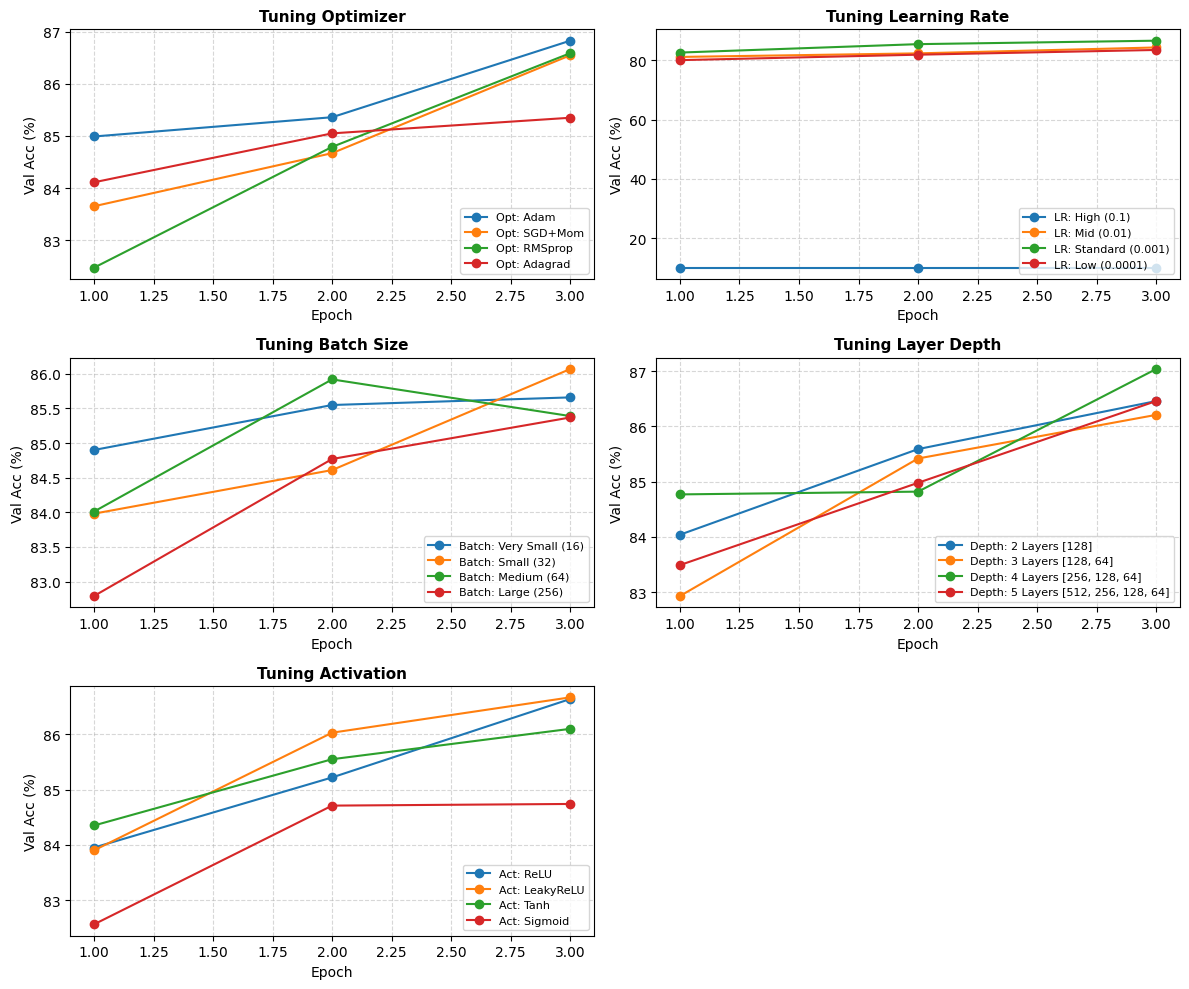

In [9]:
# 1. Display Summary DataFrame Table
df_results = pd.DataFrame(results)
print("\n" + "="*85)
print("                        HYPERPARAMETER TUNING SUMMARY TABLE")
print("="*85)
display(df_results)

# 2. Plot Category-wise Accuracies
categories = [c for c in df_results["Category"].unique() if c != "Optimized Model"]
plt.figure(figsize=(12, 10))

for idx, cat in enumerate(categories, 1):
    plt.subplot(3, 2, idx)
    sub_df = df_results[df_results["Category"] == cat]

    for _, row in sub_df.iterrows():
        exp_name = row["Experiment Name"]
        acc_history = histories[exp_name]['val_acc']
        plt.plot(range(1, 4), [a * 100 for a in acc_history], marker='o', label=exp_name)

    plt.title(f"Tuning {cat}", fontsize=11, fontweight='bold')
    plt.xlabel("Epoch")
    plt.ylabel("Val Acc (%)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.show()